# 01 · Exploratory data analysis
Human / AI / fusion texts (GhostWriter subset). Figures are saved to `images/` for the report.

In [1]:
import sys, re, difflib
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, str(Path.cwd().parent / 'src'))
from common import DATA, ROOT, LABELS
IMG = Path(ROOT) / 'images'; IMG.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3})
COL = {'human': '#2a9d8f', 'ai': '#e76f51', 'fusion': '#8a5cf6'}
tr = pd.read_parquet(f'{DATA}/train.parquet').merge(pd.read_parquet(f'{DATA}/split.parquet'), on='id')
te = pd.read_parquet(f'{DATA}/test.parquet')
for d in (tr, te):
    d['n_words'] = d.text.str.split().str.len()
print(f'train {len(tr):,} rows, test {len(te):,} rows')

train 272,352 rows, test 25,000 rows


## 1. Class balance by language and domain

In [2]:
print(tr.label.value_counts(normalize=True).round(3).to_dict())
tab = pd.crosstab([tr.domain, tr.lang], tr.label)[LABELS]
tab['n'] = tab.sum(axis=1)
share = tab[LABELS].div(tab.n, axis=0).round(2)
display(pd.concat([tab, share.add_suffix('_%')], axis=1))
dom = pd.concat([tr.domain.value_counts(normalize=True).rename('train'),
                 te.domain.value_counts(normalize=True).rename('test')], axis=1).round(3)
display(dom)

{'ai': 0.448, 'fusion': 0.307, 'human': 0.245}


label                         human     ai  fusion      n  human_%  ai_%  \
domain                 lang                                                
arxiv_papers           en-EN    407  12050    1833  14290     0.03  0.84   
blog_authorship_corpus en-EN  12466  15684   12397  40547     0.31  0.39   
bundestag              de-DE  14479  19977   17887  52343     0.28  0.38   
cnn_news               en-EN  13395  19488   11402  44285     0.30  0.44   
euro_court_cases       en-EN   6277  11141   10160  27578     0.23  0.40   
gutenberg              de-DE     31    360      37    428     0.07  0.84   
                       en-EN    216   6359     341   6916     0.03  0.92   
house_of_commons       en-EN   6953  15298    9608  31859     0.22  0.48   
student_essays         en-EN  12506  21583   20017  54106     0.23  0.40   

label                         fusion_%  
domain                 lang             
arxiv_papers           en-EN      0.13  
blog_authorship_corpus en-EN      0.31  
bundestag              de-DE      0.34  
cnn_news               en-EN      0.26  
euro_court_cases       en-EN      0.37  
gutenberg              de-DE      0.09  
                       en-EN      0.05  
house_of_commons       en-EN      0.30  
student_essays         en-EN      0.37

,train,test
domain,,
student_essays,0.199,0.159
bundestag,0.192,0.143
cnn_news,0.163,0.197
blog_authorship_corpus,0.149,0.178
house_of_commons,0.117,0.118
euro_court_cases,0.101,0.064
arxiv_papers,0.052,0.067
gutenberg,0.027,0.074


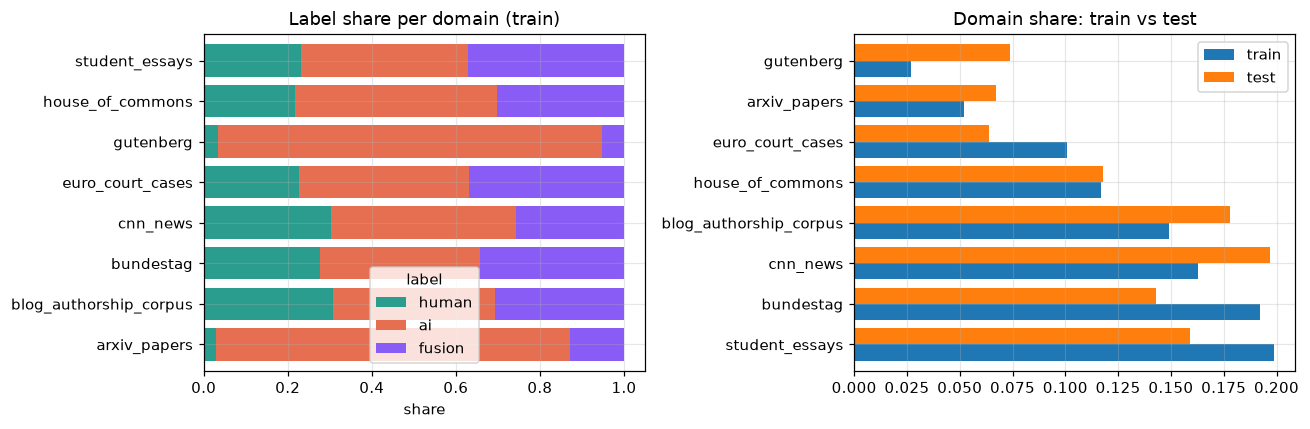

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
s = pd.crosstab(tr.domain, tr.label)[LABELS]
s.div(s.sum(axis=1), axis=0).plot.barh(stacked=True, ax=ax[0], color=[COL[l] for l in LABELS], width=.8)
ax[0].set_title('Label share per domain (train)'); ax[0].set_xlabel('share'); ax[0].set_ylabel('')
dom.plot.barh(ax=ax[1], width=.8); ax[1].set_title('Domain share: train vs test'); ax[1].set_ylabel('')
plt.tight_layout(); plt.savefig(IMG / 'eda_balance.png', bbox_inches='tight'); plt.show()

**Observations.** Overall ai 45% / fusion 31% / human 25%, so macro-F1 punishes ignoring human/fusion. The balance differs a lot by domain: arXiv and Gutenberg are ~85-90% ai with very few human/fusion texts, while blogs and Bundestag are almost balanced. German exists only in Bundestag (and a few Gutenberg books), so language is confounded with domain. Test has more Gutenberg (7.4% vs 2.7%) and arXiv - the domains with the rarest human/fusion examples - so per-domain behaviour matters. Domain and language are given in test and are used as features in the level-2 model.

## 2. Text lengths

,count,mean,std,min,10%,50%,90%,max
label,,,,,,,,
ai,121940.0,493.0,294.0,20.0,126.0,465.0,872.0,2996.0
fusion,83682.0,585.0,531.0,20.0,137.0,445.0,1137.0,3000.0
human,66730.0,578.0,473.0,20.0,110.0,481.0,1105.0,2998.0


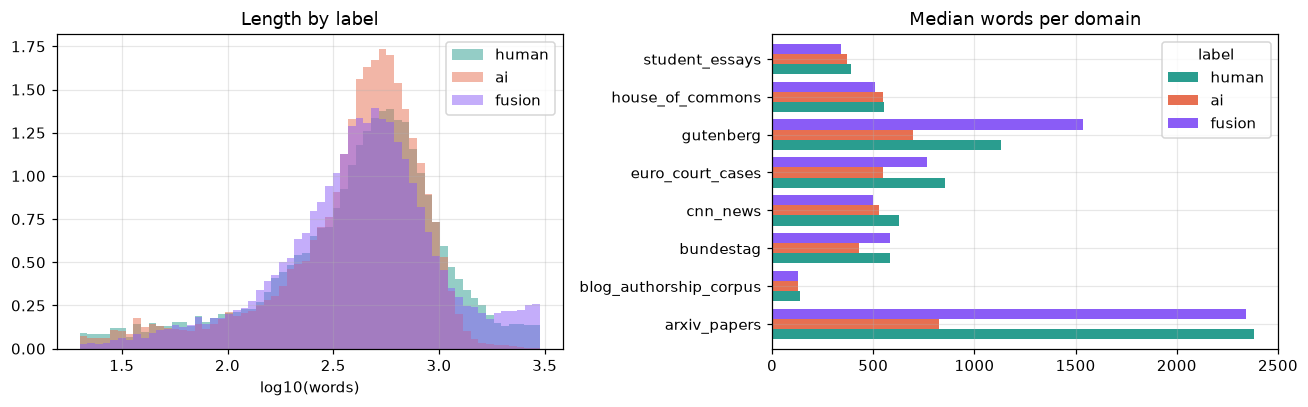

In [4]:
display(tr.groupby('label').n_words.describe(percentiles=[.1, .5, .9]).round(0))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for l in LABELS:
    ax[0].hist(np.log10(tr.n_words[tr.label == l]), bins=60, alpha=.5, density=True, label=l, color=COL[l])
ax[0].set_xlabel('log10(words)'); ax[0].legend(); ax[0].set_title('Length by label')
med = tr.groupby(['domain', 'label']).n_words.median().unstack()[LABELS]
med.plot.barh(ax=ax[1], color=[COL[l] for l in LABELS], width=.8); ax[1].set_title('Median words per domain'); ax[1].set_ylabel('')
plt.tight_layout(); plt.savefig(IMG / 'eda_lengths.png', bbox_inches='tight'); plt.show()

AI texts have a narrow length distribution (LLM outputs rarely exceed ~1000 words), while human and fusion texts have long tails up to 3000 words. Length alone is a weak signal, but very long texts are almost never ai.

## 3. Tokenisation: how much of a text fits into an encoder

In [5]:
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained('microsoft/mdeberta-v3-base')
smp = tr.sample(3000, random_state=0)
smp['n_tok'] = [len(x) for x in tok(smp.text.tolist(), add_special_tokens=False)['input_ids']]
smp['tok_per_word'] = smp.n_tok / smp.n_words
display(smp.groupby('lang')[['n_tok', 'tok_per_word']].median().round(2))
print('share of texts longer than 510 tokens:', round((smp.n_tok > 510).mean(), 3))
print('share of tokens beyond the first 510:', round((smp.n_tok - 510).clip(lower=0).sum() / smp.n_tok.sum(), 3))

,n_tok,tok_per_word
lang,,
de-DE,924.0,1.79
en-EN,685.5,1.57


share of texts longer than 510 tokens: 0.681
share of tokens beyond the first 510: 0.514


More than half of the texts do not fit into 512 tokens and about half of all tokens are beyond the first window, so plain truncation throws a lot away. This motivates random-window training and averaging over windows at inference (section 'long-text handling' in the encoder notebook).

## 4. Examples of each class

In [6]:
def show(t, n=350):
    return t[:n].replace('\n', ' / ') + ' ...'
for l in LABELS:
    for d in ['cnn_news', 'bundestag']:
        print(f'[{l} | {d}]', show(tr[(tr.label == l) & (tr.domain == d)].text.iloc[3]), '\n')

[human | cnn_news] (CNN) The U.S. Army Corps of Engineers on Thursday breached the third and final portion of a levee on the Mississippi River to help offset catastrophic floods in communities across several states. The Corps opened the final crevasse in the Birds Point-New Madrid levee, under a plan that blasted holes in the structure with hopes of easing unpreceden ... 

[human | bundestag] Sehr geehrter Herr Präsident! Sehr geehrte Damen und Herren! Die Nachhaltigkeitspolitik ist, wie so vieles, was Bundesregierungen fabrizierten, linkstotalitär. Die Grundlage aller Nachhaltigkeit, nämlich der Erhalt des Staatsvolkes, findet in ihr keinen Platz. In den letzten 50 Jahren starben in Deutschland 6,1 Millionen Menschen mehr, als geboren  ... 

[ai | cnn_news] Andres Iniesta and the Spanish National Team's Triumph at Euro 2012 The UEFA Euro 2012 tournament, held jointly by Poland and Ukraine, will be remembered not only for its thrilling matches and surprising outcomes but also for the s

[ai | bundestag] Es ist mir eine Ehre, heute hier im Bundestag zu sprechen und mich zu den von uns als AfD vertretenen Positionen zu äußern. Besonders möchte ich auf zwei dringende Missstände hinweisen: die zunehmend prozessuale Vernachlässigung unserer demokratischen Institutionen durch die Regierungsparteien und die fortschreitende Verzerrung des parlamentarische ... 

[fusion | cnn_news] The Supreme Court is used to having its decisions publicly criticized, but rarely in R-rated language spouted by a federal judge, who says the justices should just "stfu. " The remarks come from Nebraska-based Judge Richard Kopf, who has a reputation for provocative commentary on his personal blog. Kopf, an appointee of President George H. W. Bush, ... 

[fusion | bundestag] Es ist uns ein Anliegen, den Fortschritt in Deutschland voran zu treiben. In Zeiten wie diesen brauchen wir innovative Lösungen und effiziente Prozesse, um den Herausforderungen des 21. Jahrhunderts gerecht zu werden. Die aktuel

## 5. What makes fusion different
The data card says that a human text and its AI / fusion versions stay on the same side of the split, but no group id is given. `src/groups.py` reconstructs groups: word TF-IDF inside each domain, top-10 cosine neighbours, union-find over pairs with cosine > 0.4.

In [7]:
g = tr.groupby('group').label.agg(lambda s: ''.join(sorted(set(x[0] for x in s))))
print('group label-sets:', g.value_counts().to_dict())
print('group sizes:', tr.group.value_counts().value_counts().sort_index().head(6).to_dict())

group label-sets: {'a': 93888, 'fh': 45250, 'h': 8048, 'afh': 3440, 'f': 3268, 'ah': 1653, 'af': 109}
group sizes: {1: 98082, 2: 36225, 3: 16585, 4: 2491, 5: 891, 6: 556}


Most fusion texts form a pair with exactly one human text (`fh` groups), while ai texts are almost always alone: an AI version is written from scratch and shares little wording with its source, whereas fusion keeps a large part of the human text. Below we align human-fusion pairs to measure how much is kept.

,kept_sent,word_ratio,len_ratio
count,1500.00,1500.00,1500.00
mean,0.75,0.72,0.84
std,0.17,0.15,0.18
min,0.00,0.24,0.28
10%,0.50,0.51,0.58
50%,0.78,0.73,0.88
90%,0.94,0.92,1.01
max,1.00,1.00,1.79


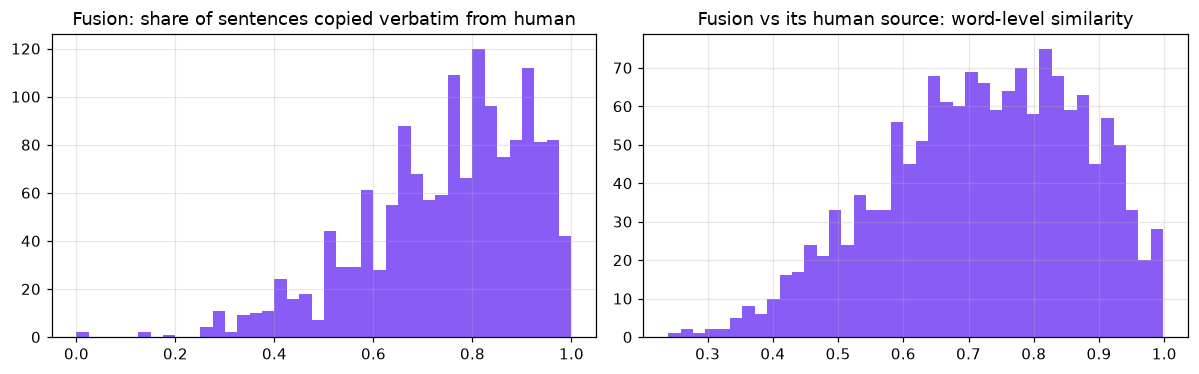

In [8]:
SENT = re.compile(r'(?<=[.!?])\s+')
pairs = []
for gid, d in tr[tr.group.isin(g[g == 'fh'].index)].groupby('group'):
    if len(d) == 2:
        pairs.append((d[d.label == 'human'].text.iloc[0], d[d.label == 'fusion'].text.iloc[0]))
    if len(pairs) == 1500: break
rows = []
for h, f in pairs:
    hs, fs = set(SENT.split(h)), SENT.split(f)
    kept = np.mean([s in hs for s in fs])
    sm = difflib.SequenceMatcher(None, h.split(), f.split(), autojunk=False)
    rows.append({'kept_sent': kept, 'word_ratio': sm.ratio(), 'len_ratio': len(f.split()) / len(h.split())})
pr = pd.DataFrame(rows)
display(pr.describe(percentiles=[.1, .5, .9]).round(2))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(pr.kept_sent, bins=40, color=COL['fusion']); ax[0].set_title('Fusion: share of sentences copied verbatim from human')
ax[1].hist(pr.word_ratio, bins=40, color=COL['fusion']); ax[1].set_title('Fusion vs its human source: word-level similarity')
plt.tight_layout(); plt.savefig(IMG / 'eda_fusion.png', bbox_inches='tight'); plt.show()

In [9]:
h, f = pairs[7]
sm = difflib.SequenceMatcher(None, h.split(), f.split(), autojunk=False)
out = []
for op, i1, i2, j1, j2 in sm.get_opcodes()[:40]:
    w = ' '.join(f.split()[j1:j2])
    out.append(w if op == 'equal' else f'[[{w}]]')
print('fusion text, LLM-changed spans in [[...]]:\n', ' '.join(out)[:1500])

fusion text, LLM-changed spans in [[...]]:
 well oh well... ok... i really screwed up my damn exams lah! wah lau... i have already scored an impressive result card of, 2 Fs, a B for chinese and a D7 or C6 for GP! haha... yup! wonderful right?! well... i can't help it lah, too pro already! yup! All that is left is to get back my E8 result than my dream of getting 3 Fs will be fulfilled! Damn it lah! wah lau! [[Here is the reconstructed missing section, approximately 28 words in length, seamlessly filling the gap between the beginning]] and [[end of]] the [[article: Reconstructed Missing Section: "Anyway, moving on from my exam debacle, I]] had a [[pretty eventful day at school]] with [[friends. We had a blast during recess, which somehow led to..." Verification: * Language & Tone: Informal, colloquial Singaporean English (e.g., "lah", "wah lau") matches the original. * Topic & Context: Transitions from discussing exams to school life with friends, aligning with the article's lighthearte

**Observation.** A fusion text keeps a part of the human sentences verbatim and replaces / inserts others, and the changed spans come in contiguous blocks. A fusion text is therefore *locally* human and *locally* AI, which is why fusion is the hardest class: a short window can look entirely human. The leaked prompt answers (example above, counts in section 6) ("reconstructed missing section ... Word Count") show how fusion was produced: the middle of a human text was removed and an LLM wrote the gap. Two consequences for modelling: (1) looking at the whole text (all windows) should help, and per-window disagreement is itself a fusion signal; (2) features that measure inconsistency inside a text (spread of per-segment perplexity / style) should separate fusion from both pure classes.

## 6. A few style statistics by class

In [10]:
st = pd.read_parquet(Path(ROOT) / 'preds' / 'stylo_sub.parquet').merge(tr[['id', 'label']], on='id')
cols = ['sent_mean', 'sent_cv', 'wlen_mean', 'ttr', 'p_dash_em', 'p_quote_curly', 'space_before_punct',
        'w_furthermore', 'w_crucial', 'blk_wlen_std']
display(st.groupby('label')[cols].mean().loc[LABELS].T.round(3))   # means: most rare-token rates have median 0

label,human,ai,fusion
sent_mean,19.139,18.650,17.741
sent_cv,0.632,0.460,0.600
wlen_mean,4.748,5.301,4.926
ttr,0.589,0.631,0.603
p_dash_em,0.007,0.066,0.015
p_quote_curly,0.071,0.166,0.067
space_before_punct,0.438,0.126,0.339
w_furthermore,0.003,0.026,0.027
w_crucial,0.002,0.046,0.024
blk_wlen_std,0.282,0.310,0.373


Leftover LLM meta-text (share of texts matching a pattern). Fusion was produced by asking an LLM to fill a removed middle part of a human text, and sometimes the prompt answer leaks into the text:

In [11]:
pats = {'missing section/part': r'(?i)missing (?:section|part|passage)', 'reconstruct': r'(?i)reconstruct',
        'word count': r'(?i)word count', 'markdown heading': r'(?m)^#+ '}
display(pd.DataFrame({k: tr.text.str.contains(v).groupby(tr.label).mean() for k, v in pats.items()}).loc[LABELS].T.round(4))

label,human,ai,fusion
missing section/part,0.0001,0.0004,0.0464
reconstruct,0.0056,0.0098,0.0327
word count,0.0000,0.0074,0.0045
markdown heading,0.0000,0.0147,0.0000


AI texts have more regular sentence lengths (lower coefficient of variation), longer words and more typical LLM vocabulary; fusion sits between human and ai on most statistics, consistent with a mixture, and has the largest spread of word length between 60-word blocks (`blk_wlen_std`) - the inconsistency we expected. Leaked meta-text appears in only ~5% of fusion texts, so it is a useful n-gram cue but not the main signal.

## 7. Validation design

In [12]:
v = tr[tr.fold == 0]
print('val rows:', len(v), '| label share', v.label.value_counts(normalize=True).round(3).to_dict())
print('groups shared between val and the rest:', len(set(v.group) & set(tr[tr.fold != 0].group)))

val rows: 27230 | label share {'ai': 0.448, 'fusion': 0.307, 'human': 0.245}


groups shared between val and the rest: 0


Fold 0 of a 10-fold StratifiedGroupKFold (groups above, strata = domain x label) is the fixed validation set for all comparisons; transformers and the models compared with them use a fixed 50k subsample of the remaining folds (whole groups). A random split would put a human text in train and its fusion copy in val, and the fusion detector would be rewarded for memorising the human text.